# CNN 2 - LeNet com Imagens tratadas

In [1]:
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, matplotlib.pyplot as plt
from src.analysis import cnn2
D = cnn2.DOMAINS
df = cnn2.load_tidy(Path('multirun/cnn_test2'))
print(df.groupby('source').seed.nunique().to_dict(), len(df))

{'big': 20, 'medium': 20, 'small': 20} 180


## Resumo por origem

In [2]:
summ = cnn2.mean_sd_ci(df, ['source', 'target'])
summ.to_csv('reports/cnn_2/summary_source_target.csv', index=False)
pd.set_option('display.width', 250, 'display.max_colwidth', 60)
cnn2.fmt_table(summ)

,source,target,n,roc_auc,pr_auc,recall_malignant,macro_f1,balanced_acc
0,big,big,20,0.819 ± 0.011 (IC ±0.005),0.864 ± 0.015 (IC ±0.007),0.800 ± 0.065 (IC ±0.031),0.745 ± 0.017 (IC ±0.008),0.747 ± 0.013 (IC ±0.006)
1,big,medium,20,0.677 ± 0.014 (IC ±0.007),0.504 ± 0.027 (IC ±0.012),0.639 ± 0.056 (IC ±0.026),0.608 ± 0.020 (IC ±0.009),0.630 ± 0.017 (IC ±0.008)
2,big,small,20,0.643 ± 0.028 (IC ±0.013),0.462 ± 0.029 (IC ±0.013),0.739 ± 0.127 (IC ±0.059),0.547 ± 0.035 (IC ±0.016),0.598 ± 0.038 (IC ±0.018)
3,medium,big,20,0.749 ± 0.017 (IC ±0.008),0.817 ± 0.016 (IC ±0.007),0.685 ± 0.104 (IC ±0.049),0.669 ± 0.024 (IC ±0.011),0.682 ± 0.021 (IC ±0.010)
4,medium,medium,20,0.738 ± 0.022 (IC ±0.010),0.632 ± 0.030 (IC ±0.014),0.635 ± 0.105 (IC ±0.049),0.640 ± 0.044 (IC ±0.020),0.658 ± 0.025 (IC ±0.012)
5,medium,small,20,0.650 ± 0.022 (IC ±0.010),0.501 ± 0.034 (IC ±0.016),0.668 ± 0.086 (IC ±0.040),0.577 ± 0.027 (IC ±0.013),0.607 ± 0.021 (IC ±0.010)
6,small,big,20,0.675 ± 0.016 (IC ±0.008),0.794 ± 0.015 (IC ±0.007),0.387 ± 0.049 (IC ±0.023),0.562 ± 0.023 (IC ±0.011),0.626 ± 0.016 (IC ±0.008)
7,small,medium,20,0.679 ± 0.022 (IC ±0.010),0.531 ± 0.031 (IC ±0.014),0.356 ± 0.060 (IC ±0.028),0.615 ± 0.024 (IC ±0.011),0.611 ± 0.022 (IC ±0.010)
8,small,small,20,0.773 ± 0.021 (IC ±0.010),0.640 ± 0.043 (IC ±0.020),0.521 ± 0.066 (IC ±0.031),0.693 ± 0.029 (IC ±0.014),0.686 ± 0.027 (IC ±0.013)


## Matriz origem -> destino

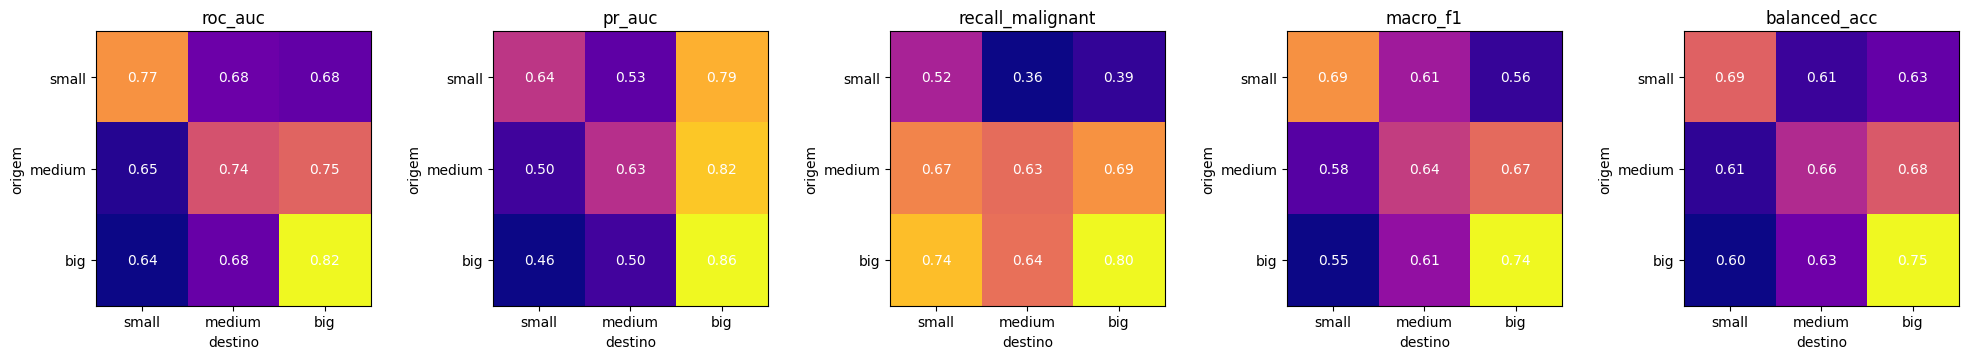

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, m in zip(axes, cnn2.METRICS):
    M = df.groupby(['source', 'target'])[m].mean().unstack().loc[D, D]
    im = ax.imshow(M.values, cmap='plasma'); ax.set_title(m)
    ax.set_xticks(range(3), D); ax.set_yticks(range(3), D); ax.set_xlabel('destino'); ax.set_ylabel('origem')
    for i in range(3):
        for j in range(3): ax.text(j, i, f'{M.values[i, j]:.2f}', ha='center', va='center', color='w')
fig.tight_layout(); plt.show()

## Épocas até o melhor val AUC

        mean  std  min  median  max
source                             
big     12.9  5.9    7    11.0   35
medium   6.9  2.0    3     7.0   10
small   20.8  6.3   11    20.5   31
         mean    std
source              
big     0.851  0.012
medium  0.816  0.011
small   0.797  0.014


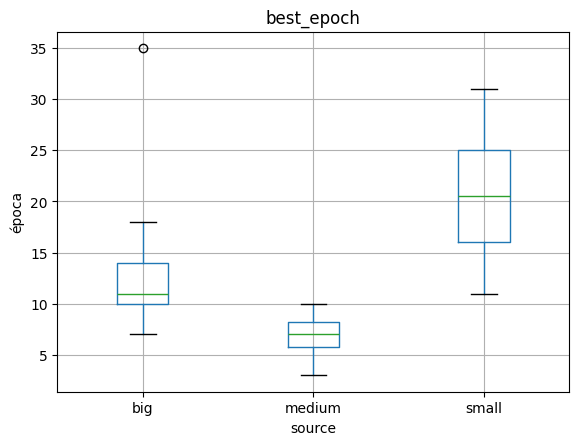

In [7]:
runs = df.drop_duplicates(['source', 'seed'])
print(runs.groupby('source').best_epoch.agg(['mean', 'std', 'min', 'median', 'max']).round(1))
print(runs.groupby('source').best_val_auc.agg(['mean', 'std']).round(3))
runs.boxplot(column='best_epoch', by='source'); plt.suptitle(''); plt.ylabel('época'); plt.show()

## Curva de aprendizado

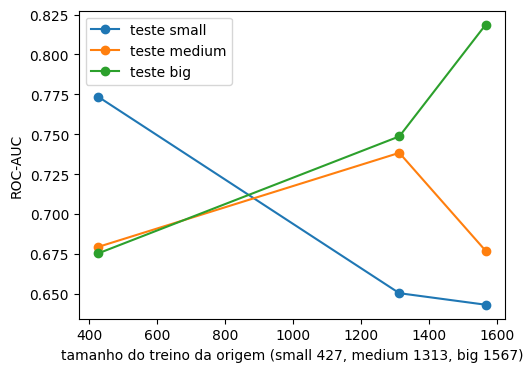

In [8]:
cmp = df.groupby(['source', 'target']).roc_auc.mean().unstack().loc[D, D]
fig, ax = plt.subplots(figsize=(5.5, 4))
for tgt in D:
    ax.plot([cnn2.N_TRAIN[s] for s in D], cmp[tgt].loc[D], 'o-', label=f'teste {tgt}')
ax.set_xlabel('tamanho do treino da origem (small 427, medium 1313, big 1567)'); ax.set_ylabel('ROC-AUC')
ax.legend(); plt.show()

## Volume x domínio

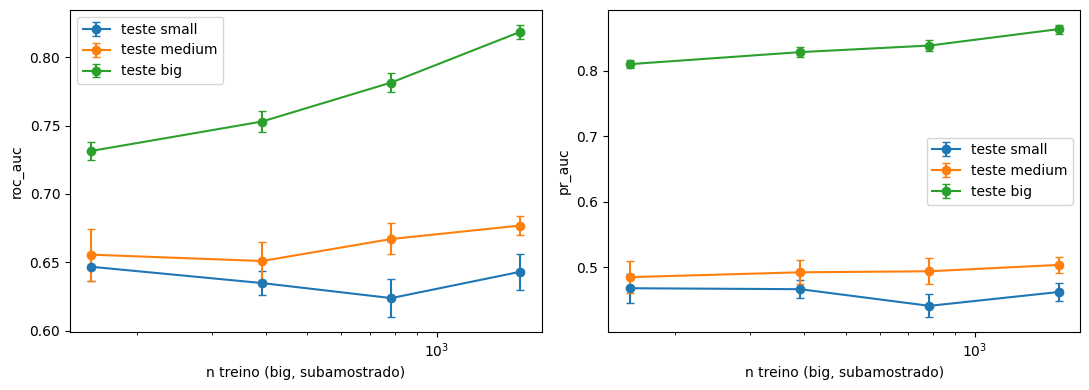

,train_fraction,n_train,target,n,roc_auc_mean,roc_auc_sd,roc_auc_ci95,pr_auc_mean,pr_auc_sd,pr_auc_ci95,balanced_acc_mean,balanced_acc_sd,balanced_acc_ci95
0,0.10,157,big,20,0.731,0.015,0.007,0.810,0.013,0.006,0.657,0.037,0.017
1,0.10,157,medium,20,0.656,0.041,0.019,0.485,0.052,0.024,0.595,0.040,0.019
2,0.10,157,small,20,0.647,0.022,0.010,0.468,0.047,0.022,0.596,0.038,0.018
3,0.25,392,big,20,0.753,0.017,0.008,0.829,0.016,0.008,0.683,0.019,0.009
4,0.25,392,medium,20,0.651,0.030,0.014,0.492,0.039,0.018,0.595,0.026,0.012
5,0.25,392,small,20,0.635,0.019,0.009,0.466,0.030,0.014,0.607,0.034,0.016
6,0.50,784,big,20,0.781,0.016,0.007,0.839,0.019,0.009,0.706,0.025,0.012
7,0.50,784,medium,20,0.667,0.024,0.011,0.494,0.042,0.020,0.619,0.028,0.013
8,0.50,784,small,20,0.624,0.030,0.014,0.441,0.038,0.018,0.588,0.038,0.018
9,1.00,1567,big,20,0.819,0.011,0.005,0.864,0.015,0.007,0.747,0.013,0.006


In [9]:
frac = cnn2.load_tidy(Path('multirun/frac_sweep'))
full = df[df.source == 'big'].assign(train_fraction=1.0, n_train=cnn2.N_TRAIN['big'])
allf = pd.concat([frac, full], ignore_index=True)
fs = cnn2.mean_sd_ci(allf, ['train_fraction', 'n_train', 'target'], ['roc_auc', 'pr_auc', 'balanced_acc'])
fs.to_csv('reports/cnn_2/learning_curve_big_subsample.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, m in zip(axes, ['roc_auc', 'pr_auc']):
    for tgt in D:
        g = fs[fs.target == tgt].sort_values('n_train')
        ax.errorbar(g.n_train, g[f'{m}_mean'], yerr=g[f'{m}_ci95'], marker='o', capsize=3, label=f'teste {tgt}')
    ax.set_xscale('log'); ax.set_xlabel('n treino (big, subamostrado)'); ax.set_ylabel(m); ax.legend()
fig.tight_layout(); plt.show()
fs.round(3)

### Volume vs. domínio, no mesmo n
Compara o big subamostrado ao small/medium completos em tamanho parecido.

In [10]:
ref = df[df.target == df.source].groupby('source').roc_auc.mean()
sub = allf[allf.target == 'big'].groupby('n_train').roc_auc.mean()
print('AUC in-domain completo:', ref.round(3).to_dict())
print('AUC no big test, treino big subamostrado:'); print(sub.round(3))

AUC in-domain completo: {'big': 0.819, 'medium': 0.738, 'small': 0.773}
AUC no big test, treino big subamostrado:
n_train
157     0.731
392     0.753
784     0.781
1567    0.819
Name: roc_auc, dtype: float64
